# F.I.L. FOODS Algorithm Benchmarking Analysis

**Project:** F.I.L. FOODS Meal Management System  
**Team:** Relish (Group 4) - Hanna Joy L. Argueza, Michael Angelo C. Gamet, Jetrick M. Roxas, Lourdes Jed R. Villanueva  
**Course:** III-BCSAD, S.Y. 2026-2027  
**Repository:** https://github.com/colossalshub/fil-foods  
**Document date:** 14 November 2026

## 1. Introduction and problem statement

F.I.L. Foods is a Filipino meal-management application. This report evaluates typo-tolerant search for orders/FAQ content and daily meal selection under nutrition targets. The Python order/FAQ matcher implements workbook acceptance rules; it is **not** claimed to be integrated into Expo search boxes. The client meal-catalog search (`fuzzySearchMeals`) remains separate, with different rules. The nutrition solver is a Python port of the existing TypeScript solver.

### Problem statement

Exact-text lookup fails when customers or staff mistype names, order numbers, or FAQ terms. Search must respect role visibility, status filters, token semantics, and ranking without "correcting" order numbers. Separately, selecting a daily menu by choosing each slot independently can miss a good combined plan or violate calorie/fat ceilings; exhaustive enumeration can find a best feasible combination, but its search space grows multiplicatively with meals per slot. This study compares these approaches under their stated objectives without mixing datasets or outputs.

### Algorithms and concrete examples

| Problem | Algorithms compared | Example input -> expected output |
|---|---|---|
| Order/FAQ lookup | Visible-text substring baseline; Levenshtein; optimal string alignment (OSA / restricted Damerau) | Admin `Mria` -> order `00349`; staff `Reyes` -> no result; FAQ `reset pasword` -> `account-password` |
| Daily meal plan | Per-slot equal-share greedy choice; exhaustive one-meal-per-slot enumeration | Three slots with a 1,800 kcal ceiling -> one selected breakfast, lunch, and dinner, with feasibility and totals reported |

Search returns an ordered list of matching IDs (and records for a UI); nutrition returns `{ok, exactMatch, meals, totals, score}`. `ok` means a calorie/fat-feasible combination exists; `exactMatch` additionally requires meeting the positive protein minimum. If no feasible combination exists but every slot has candidates, the solver returns the closest combination with `ok=False`.

### Scope boundary

Order/FAQ search is specified by ADM-11, KIT-11, DEL-11, and USR-27 acceptance examples. The existing meal-catalog matcher in `frontend/src/services/orderService.ts` has different behavior and is not benchmarked here. The nutrition solver in `frontend/src/services/nutritionService.ts` is ported for analysis; this notebook does not claim that Python code runs in the Expo application.

### Processing pipeline

```text
Acceptance examples + FAQ text -> normalize / role and status filter -> substring / Levenshtein / OSA matcher -> ranked record IDs -> acceptance and failure analysis
Synthetic order lists -> same generated inputs -> repeated runtime and peak-memory measurements
Meal candidates + daily targets -> slot filtering -> greedy or exhaustive selection -> plan, totals, feasibility -> quality / cost comparison
```


## 2. Environment, reproducibility, and engineering rationale

This revision was validated with CPython `3.14.6` on Windows 11 (AMD64, 20 logical CPUs; environment output records the observed hardware and package versions). Future runs print their own exact Python version. The notebook uses the Python standard library plus Matplotlib for plots; Matplotlib is pinned to `3.11.2` and the notebook enforces and reports that version. NumPy is reported as an environment detail; it is not used by the benchmark logic. No account key, hosted service, training, or random model fitting is involved. Acceptance examples are deterministic and are not split into train/validation/test data. Synthetic timing data is generated separately.

### Engineering rationale

The substring baseline is simple and fast but cannot repair spelling errors. Levenshtein adds insertion/deletion/substitution correction; OSA adds adjacent-transposition correction at the same asymptotic dynamic-programming cost. These progressively isolate typo handling while keeping normalization, fields, filters, ranking, acceptance cases, and evaluation fixed. The original workbook cases happen to give Levenshtein and OSA the same pass count: the six-letter `carols`/`carlos` swap is allowed two edits, so both accept it. OSA remains the specification-aligned choice because it counts an adjacent transposition as one edit. The separate four-letter `Jhon`/`John` diagnostic has a one-edit budget: OSA accepts the transposition while Levenshtein rejects it. This demonstrates the intended match-quality distinction; it does not change the acceptance criteria. OSA uses the same `O(mn)` time/space dynamic program but performs an additional transposition check, so the benchmark can show a runtime cost for that capability.

The exhaustive nutrition solver is retained because it selects minimum weighted-deviation feasible combinations under the current implementation; its work grows as `O(product(n_i))` combinations. The greedy equal-share baseline is cheaper but makes slot decisions independently and can miss the global optimum. Implementation and objective are held fixed; this is not a proposal to change product behavior.

### Reproducibility controls

`DATASET_SEED = 20261112` seeds synthetic order-name and nutrition-menu generation. Each list size derives a local `random.Random` seed, so generation does not mutate the global RNG. The two fixed nutrition quality scenarios are explicitly listed, not sampled; no randomization is used for acceptance evaluation. Timing uses one warm-up, repeated `time.perf_counter()` measurements, median/Q1/Q3/IQR, and a separate `tracemalloc` peak. Timing is environment-specific and should be rerun after restarting the Python kernel. The source notebook is the executable record; outputs are refreshed by the final clean top-to-bottom execution.


In [1]:
import importlib
from importlib import metadata
import math
import platform
import random
import re
import statistics
import sys
import time
import tracemalloc
import unicodedata

MATPLOTLIB_PIN = "3.11.2"
try:
    installed_matplotlib = metadata.version("matplotlib")
except metadata.PackageNotFoundError:
    installed_matplotlib = None
if installed_matplotlib != MATPLOTLIB_PIN:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", f"matplotlib=={MATPLOTLIB_PIN}"])

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

DATASET_SEED = 20261112
SEARCH_SIZES = [100, 500, 1_000, 5_000, 10_000]
SEARCH_REPEATS = 5
SLOT_SWEEP = [4, 8, 12, 16, 24]
SLOT_REPEATS = 5

print("Python", sys.version.replace("\n", " "))
print("matplotlib", matplotlib.__version__, "(pinned", MATPLOTLIB_PIN + ")")
print("NumPy", __import__("numpy").__version__)
print("hardware", platform.machine(), "logical_cpus", __import__("os").cpu_count())
print("platform", platform.platform())
print("processor", platform.processor() or "(not reported)")
print("cpu_count", __import__("os").cpu_count())
try:
    import psutil
    print(f"memory_total_gb {psutil.virtual_memory().total / (1024 ** 3):.2f}")
except ImportError as exc:
    print("memory_total_gb unavailable", type(exc).__name__)
print("DATASET_SEED", DATASET_SEED)
print("SEARCH_SIZES", SEARCH_SIZES)
print("SEARCH_REPEATS", SEARCH_REPEATS)

def measure(function, repeats):
    function()  # one untimed warm-up, consistent across measured functions
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        samples.append((time.perf_counter() - start) * 1000)
    q1, _, q3 = statistics.quantiles(samples, n=4, method="inclusive")
    tracemalloc.start()
    tracemalloc.reset_peak()
    function()
    _, peak_bytes = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return {"median_ms": statistics.median(samples), "q1_ms": q1, "q3_ms": q3, "iqr_ms": q3 - q1, "peak_bytes": peak_bytes, "trials": len(samples)}


Python 3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
matplotlib 3.11.2 (pinned 3.11.2)
NumPy 2.5.3
hardware AMD64 logical_cpus 20
platform Windows-11-10.0.26200-SP0
processor Intel64 Family 6 Model 151 Stepping 2, GenuineIntel
cpu_count 20
memory_total_gb 15.79
DATASET_SEED 20261112
SEARCH_SIZES [100, 500, 1000, 5000, 10000]
SEARCH_REPEATS 5


## 3. Search mathematics and implementation

Normalization lowercases text, removes accents, and turns punctuation into spaces. A one-character normalized query returns the filtered list unchanged (the workbook's minimum-query behavior), and each longer query token must match. Exact, prefix-partial, and typo matches are ranked in that order; equal tiers are newest-first. Staff searches first names and order numbers; Admin also sees last names; FAQ matching uses question plus answer. Order-number tokens are digit-only containment/full-number matches and are never fuzzy-corrected.

### Edit-distance recurrence

For strings `a` and `b`, Levenshtein uses `D[i,0]=i`, `D[0,j]=j`, and `D[i,j] = min(D[i-1,j]+1, D[i,j-1]+1, D[i-1,j-1]+[a_i != b_j])`. OSA also considers `D[i-2,j-2]+1` when adjacent characters are reversed. Both implementations below allocate a `(len(a)+1) by (len(b)+1)` matrix, so time and space are `O(mn)` per compared pair. A complete search scans `N` records and visible words; approximate work is `O(N*W*m*n)` for a representative candidate length `W`, plus ranking. A name-word substring baseline accepts when a normalized query token occurs contiguously in a visible stored word (`q in w`); its scan is `O(N*L)` for total searchable text length `L`, plus result sorting. Prefix/substrings scan compared text linearly. `typo_budget` implements the business thresholds (0 for lengths below 3, 1 for 3-5, 2 for 6+).

The next code implements these equations in `levenshtein`, `osa_distance`, and `token_kind`; `match_token` enforces order-number behavior and `search_records` applies whole-query, visibility, filtering, and ordering rules. OSA is restricted Damerau-Levenshtein, not unrestricted Damerau distance. On the preserved acceptance set, both edit-distance variants pass the same cases because `carols`/`carlos` is length six and therefore has a two-edit budget. The separate `Jhon`/`John` diagnostic is length four (one-edit budget): OSA returns distance 1 and matches, while Levenshtein returns distance 2 and rejects. OSA is used because the stated algorithm rule treats adjacent swaps as one typo; its extra recurrence check can cost runtime without changing the existing acceptance pass count.


In [2]:
def normalize(value):
    text = unicodedata.normalize("NFD", value or "")
    text = "".join(ch for ch in text if unicodedata.category(ch) != "Mn")
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def digits_only(value):
    return "".join(ch for ch in (value or "") if ch.isdigit())


def osa_distance(a, b):
    """One adjacent transposition counts as a single change."""
    if a == b:
        return 0
    la, lb = len(a), len(b)
    dist = [[0] * (lb + 1) for _ in range(la + 1)]
    for i in range(la + 1):
        dist[i][0] = i
    for j in range(lb + 1):
        dist[0][j] = j
    for i in range(1, la + 1):
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dist[i][j] = min(dist[i - 1][j] + 1, dist[i][j - 1] + 1, dist[i - 1][j - 1] + cost)
            if i > 1 and j > 1 and a[i - 1] == b[j - 2] and a[i - 2] == b[j - 1]:
                dist[i][j] = min(dist[i][j], dist[i - 2][j - 2] + 1)
    return dist[la][lb]


def levenshtein(a, b):
    if a == b:
        return 0
    la, lb = len(a), len(b)
    dist = [[0] * (lb + 1) for _ in range(la + 1)]
    for i in range(la + 1):
        dist[i][0] = i
    for j in range(lb + 1):
        dist[0][j] = j
    for i in range(1, la + 1):
        for j in range(1, lb + 1):
            cost = 0 if a[i - 1] == b[j - 1] else 1
            dist[i][j] = min(dist[i - 1][j] + 1, dist[i][j - 1] + 1, dist[i - 1][j - 1] + cost)
    return dist[la][lb]


def typo_budget(word):
    size = len(word)
    if size < 3:
        return 0
    if size <= 5:
        return 1
    return 2


TIER = {"exact": 0, "partial": 1, "fuzzy": 2}


def token_kind(query_word, candidate, distance):
    if query_word == candidate:
        return "exact"
    if len(query_word) >= 2 and candidate.startswith(query_word):
        return "partial"
    allowed = typo_budget(query_word)
    if allowed == 0:
        return None
    dist = distance(query_word, candidate)
    if dist <= allowed and abs(len(candidate) - len(query_word)) <= allowed:
        return "fuzzy"
    return None


def match_token(token, words, order_digits, distance):
    if token.isdigit():
        if token and order_digits and token in order_digits:
            full = order_digits.lstrip("0") or "0"
            if token == order_digits or token == full:
                return "exact"
            return "partial"
        return None
    best = None
    for word in words:
        kind = token_kind(token, word, distance)
        if kind is None:
            continue
        if best is None or TIER[kind] < TIER[best]:
            best = kind
            if best == "exact":
                break
    return best


def order_words(row, role):
    text = f"{row['first']} {row['last']}" if role == "admin" else row["first"]
    return normalize(text).split(" "), digits_only(row["number"])


def faq_words(row, role):
    return normalize(f"{row['question']} {row['answer']}").split(" "), ""


def search_records(records, query, role="admin", status=None, distance=osa_distance, words_of=order_words):
    pool = [row for row in records if not status or row.get("status") == status]
    if len(normalize(query)) < 2:
        return list(pool)
    tokens = [token for token in normalize(query).split(" ") if token]
    hits = []
    for index, row in enumerate(pool):
        words, order_digits = words_of(row, role)
        kinds = []
        matched = True
        for token in tokens:
            kind = match_token(token, words, order_digits, distance)
            if kind is None:
                matched = False
                break
            kinds.append(kind)
        if matched:
            tier = max(TIER[kind] for kind in kinds)
            hits.append((tier, -row.get("stamp", 0), index, row))
    hits.sort()
    return [row for _, _, _, row in hits]


def ids_of(rows):
    return [row["id"] for row in ids_of.__wrapped__] if False else [row["id"] for row in rows]

print("swap carols/carlos OSA", osa_distance("carols", "carlos"), "Levenshtein", levenshtein("carols", "carlos"))
print("swap jhon/john OSA", osa_distance("jhon", "john"), "Levenshtein", levenshtein("jhon", "john"))


swap carols/carlos OSA 1 Levenshtein 2
swap jhon/john OSA 1 Levenshtein 2


## 4. Acceptance datasets

The five orders are the sample list in ADM-11, KIT-11, and DEL-11. The nine FAQ records retain the wording in `frontend/src/data/helpContent.ts`, not rewritten questions. These are **acceptance data**, distinct from synthetic timing catalogs and synthetic nutrition menus generated later. `delivry` can match only an entry whose own question or answer contains a word within the configured edit budget of `delivery`.

In [3]:
ORDERS = [
    {"id": "00350", "number": "00350", "first": "Juan", "last": "Dela Cruz", "status": "Pending", "stamp": 5},
    {"id": "00349", "number": "00349", "first": "Maria", "last": "Santos", "status": "Preparing", "stamp": 4},
    {"id": "00348", "number": "00348", "first": "Carlos", "last": "Reyes", "status": "Delivered", "stamp": 3},
    {"id": "00347", "number": "00347", "first": "Ana", "last": "Garcia", "status": "Cancelled", "stamp": 2},
    {"id": "00346", "number": "00346", "first": "Mark", "last": "Villanueva", "status": "Delivered", "stamp": 1},
]

FAQ = [
    {"id": "account-create", "question": "How do I create an account?", "answer": "Tap Create an account on the login screen, fill in your details, verify your contact method, then complete your profile.", "stamp": 0},
    {"id": "account-password", "question": "How do I reset my password?", "answer": "On the login screen tap Forgot password?, enter your username, verify the code, then set a new password.", "stamp": 0},
    {"id": "account-google", "question": "Can I sign in with Google?", "answer": "Yes. Use Continue with Google on login or create account. You can link Google to an existing username and password account.", "stamp": 0},
    {"id": "ordering-place", "question": "How do I place an order?", "answer": "Browse Meals, choose items and quantities, review your cart from Meals, then confirm payment and delivery details.", "stamp": 0},
    {"id": "ordering-change", "question": "Can I change my order after confirming?", "answer": "Contact support as soon as possible. Changes depend on kitchen timing and order status.", "stamp": 0},
    {"id": "delivery-window", "question": "When will my order arrive?", "answer": "Delivery windows appear at checkout. Orders shows updates once the kitchen dispatches your order.", "stamp": 0},
    {"id": "delivery-pickup", "question": "How does pickup work?", "answer": "Choose pickup at checkout, then collect at the listed location when your order is ready.", "stamp": 0},
    {"id": "health-allergies", "question": "Why do you ask for allergies and health conditions?", "answer": "We use your profile to flag meals that may conflict with recorded allergies or dietary needs.", "stamp": 0},
    {"id": "health-update", "question": "How do I update my dietary information?", "answer": "Open Account and edit Health conditions, Dietary restrictions, or Food allergies. Save after each change.", "stamp": 0},
]

# difficulty is used for the quality table. expected ids are the workbook outcome.
ORDER_CASES = [
    ("Exact", "admin", "Maria Santos", None, ["00349"]),
    ("Minor", "admin", "Mria", None, ["00349"]),
    ("Swap", "admin", "carols", None, ["00348"]),
    ("Minor", "admin", "Villanueba", None, ["00346"]),
    ("Word order", "admin", "Garcia Ana", None, ["00347"]),
    ("Partial", "admin", "Mar", None, ["00349", "00346"]),
    ("Order number", "admin", "350", None, ["00350"]),
    ("Order number", "admin", "#00350", None, ["00350"]),
    ("Wrong digit", "admin", "00359", None, []),
    ("Too different", "admin", "Jon", None, []),
    ("Status filter", "admin", "Mria", "Delivered", []),
    ("Status filter", "admin", "Mria", "Preparing", ["00349"]),
    ("Short query", "admin", "p", None, [row["id"] for row in ORDERS]),
    ("Last name", "admin", "Reyes", None, ["00348"]),
    ("Case and space", "admin", "  MARIA   santos ", None, ["00349"]),
    ("Minor", "staff", "Mria", None, ["00349"]),
    ("Swap", "staff", "carols", None, ["00348"]),
    ("Partial", "staff", "Mar", None, ["00349", "00346"]),
    ("Order number", "staff", "350", None, ["00350"]),
    ("Order number", "staff", "#00350", None, ["00350"]),
    ("Hidden last name", "staff", "Reyes", None, []),
    ("Hidden last name", "staff", "Santos", None, []),
    ("Hidden last name", "staff", "Villanueba", None, []),
    ("Wrong digit", "staff", "00359", None, []),
    ("Too different", "staff", "Jon", None, []),
    ("Status filter", "staff", "Mria", "Delivered", []),
]

FAQ_CASES = [
    ("FAQ exact", "password", ["account-password", "account-google"]),
    ("FAQ case", "PASSWORD ", ["account-password", "account-google"]),
    ("FAQ minor", "pasword", ["account-password", "account-google"]),
    ("FAQ two words", "reset pasword", ["account-password"]),
    ("FAQ delivery", "delivry", ["ordering-place", "delivery-window"]),
    ("FAQ short", "p", [row["id"] for row in FAQ]),
    ("FAQ miss", "zzzz", []),
]

print("sample orders", len(ORDERS), "faq entries", len(FAQ), "order cases", len(ORDER_CASES), "faq cases", len(FAQ_CASES))


sample orders 5 faq entries 9 order cases 26 faq cases 7


### 4.1 Dataset integrity checks (acceptance data)

These checks run immediately after inline acceptance records load and before any matcher evaluation. The five workbook orders and nine FAQ records are the actual acceptance datasets. Synthetic order and meal records are generated later and used only for performance experiments; they are not acceptance observations or customer data.

In [4]:
from collections import Counter

def audit_records(name, records, required, key):
    missing = {field: sum(row.get(field) is None or row.get(field) == "" for row in records) for field in required}
    duplicate_keys = [value for value, count in Counter(row.get(key) for row in records).items() if count > 1]
    print(f"{name}: rows={len(records)}; missing/blank={missing}; duplicate {key}s={duplicate_keys}")
    return missing, duplicate_keys

order_missing, order_duplicate_ids = audit_records("Workbook acceptance orders", ORDERS, ["id", "number", "first", "last", "status", "stamp"], "id")
faq_missing, faq_duplicate_ids = audit_records("Current FAQ acceptance text", FAQ, ["id", "question", "answer", "stamp"], "id")
order_name_counts = Counter((normalize(row["first"]), normalize(row["last"])) for row in ORDERS)
faq_question_counts = Counter(normalize(row["question"]) for row in FAQ)
print("duplicate complete order rows", len(ORDERS) - len({tuple(sorted(row.items())) for row in ORDERS}))
print("duplicate normalized order names", {name: count for name, count in order_name_counts.items() if count > 1})
print("duplicate normalized FAQ questions", {question: count for question, count in faq_question_counts.items() if count > 1})
print("order status distribution", dict(Counter(row["status"] for row in ORDERS)))
print("FAQ id-prefix distribution", dict(Counter(row["id"].split("-")[0] for row in FAQ)))
print("order number digit-length range", (min(len(digits_only(row["number"])) for row in ORDERS), max(len(digits_only(row["number"])) for row in ORDERS)))
print("order stamp range", (min(row["stamp"] for row in ORDERS), max(row["stamp"] for row in ORDERS)))
print("name-length range", (min(len(row["first"] + " " + row["last"]) for row in ORDERS), max(len(row["first"] + " " + row["last"]) for row in ORDERS)))
print("FAQ question-length range", (min(len(row["question"]) for row in FAQ), max(len(row["question"]) for row in FAQ)))
print("boundary examples: empty query -> filtered list; one-character query 'p' -> full filtered list; order '00350' / query '350' -> match; '00359' -> no correction; OSA typo 'carols' -> Carlos")
assert not any(order_missing.values()) and not order_duplicate_ids
assert not any(faq_missing.values()) and not faq_duplicate_ids

Workbook acceptance orders: rows=5; missing/blank={'id': 0, 'number': 0, 'first': 0, 'last': 0, 'status': 0, 'stamp': 0}; duplicate ids=[]
Current FAQ acceptance text: rows=9; missing/blank={'id': 0, 'question': 0, 'answer': 0, 'stamp': 0}; duplicate ids=[]
duplicate complete order rows 0
duplicate normalized order names {}
duplicate normalized FAQ questions {}
order status distribution {'Pending': 1, 'Preparing': 1, 'Delivered': 2, 'Cancelled': 1}
FAQ id-prefix distribution {'account': 3, 'ordering': 2, 'delivery': 2, 'health': 2}
order number digit-length range (5, 5)
order stamp range (1, 5)
name-length range (10, 15)
FAQ question-length range (21, 51)
boundary examples: empty query -> filtered list; one-character query 'p' -> full filtered list; order '00350' / query '350' -> match; '00359' -> no correction; OSA typo 'carols' -> Carlos


## 5. Progressive search ablation and acceptance evaluation

Three variants are compared on identical order and FAQ acceptance cases: (1) visible-text substring matching, (2) Levenshtein edit distance, then (3) OSA with adjacent swaps counted as one. The distance function is the sole change between Levenshtein and OSA. The substring baseline keeps shared normalization, query-length gate, role-visible fields, status filter, order-number rule, all-token requirement, and newest-first ordering. Every variant is judged against the same workbook expected IDs, in order; an exact ordered-list match is one passing case.

Precision, recall, and F1 summarize specified order cases with non-empty expected results; empty expectations are checked for correct empty output and are not treated as positive-class recall. The summary reports exact-list acceptance passes across order and FAQ cases, plus efficiency on separate synthetic data. This prevents mixing small acceptance-set quality with large synthetic-list runtime.


In [5]:
def check(condition, message):
    if not condition:
        raise AssertionError(message)


def run_orders(distance):
    found = []
    for difficulty, role, query, status, expected in ORDER_CASES:
        got = ids_of(search_records(ORDERS, query, role, status, distance, order_words))
        found.append({"difficulty": difficulty, "role": role, "query": query, "status": status, "expected": expected, "got": got, "passed": got == expected})
    return found


def prf(got, expected):
    got_set, expected_set = set(got), set(expected)
    overlap = got_set & expected_set
    precision = None if not got else len(overlap) / len(got_set)
    recall = None if not expected else len(overlap) / len(expected_set)
    if recall is None:
        f1 = None
        top = 1.0 if not got else 0.0
    else:
        f1 = 0.0 if recall == 0 or not precision else 2 * precision * recall / (precision + recall)
        top = 1.0 if got and got[0] in expected_set else 0.0
    return precision, recall, f1, top


SPEC_ORDERS = run_orders(osa_distance)
LEVEN_ORDERS = run_orders(levenshtein)
check(all(row["passed"] for row in SPEC_ORDERS), "workbook order cases")

FAQ_RESULTS = []
for label, query, expected in FAQ_CASES:
    got = ids_of(search_records(FAQ, query, "faq", None, osa_distance, faq_words))
    FAQ_RESULTS.append({"label": label, "query": query, "expected": expected, "got": got, "passed": got == expected})
check(all(row["passed"] for row in FAQ_RESULTS), "workbook FAQ cases")

JOHN = [{"id": "john", "number": "00999", "first": "John", "last": "Cruz", "status": "Pending", "stamp": 1}]
JOSE = [{"id": "jose", "number": "00888", "first": "José", "last": "Rizal", "status": "Pending", "stamp": 1}]
check(ids_of(search_records(JOHN, "Jhon", "admin", None, osa_distance, order_words)) == ["john"], "4-letter swap")
check(ids_of(search_records(JOHN, "Jhon", "admin", None, levenshtein, order_words)) == [], "Levenshtein rejects a 4-letter swap")
check(ids_of(search_records(JOSE, "Jose", "admin", None, osa_distance, order_words)) == ["jose"], "accent")
DUPLICATES = [
    {"id": "dup-new", "number": "00101", "first": "Ana", "last": "Reyes", "status": "Pending", "stamp": 2},
    {"id": "dup-old", "number": "00102", "first": "Ana", "last": "Reyes", "status": "Pending", "stamp": 1},
]
UNIT_CASES = [
    ("normal exact", ids_of(search_records(ORDERS, "Maria", distance=osa_distance)), ["00349"]),
    ("empty input", ids_of(search_records([], "", distance=osa_distance)), []),
    ("empty/None query", ids_of(search_records(ORDERS, None, distance=osa_distance)), [row["id"] for row in ORDERS]),
    ("duplicate records preserve both, newest first", ids_of(search_records(DUPLICATES, "Ana", distance=osa_distance)), ["dup-new", "dup-old"]),
    ("typo and adjacent transposition", ids_of(search_records(ORDERS, "carols", distance=osa_distance)), ["00348"]),
    ("typo length boundary 2/3/5/6", [typo_budget(word) for word in ("ab", "abc", "abcde", "abcdef")], [0, 1, 1, 2]),
    ("OSA transposition boundary", osa_distance("jhon", "john"), 1),
    ("invalid/non-text normalization", normalize(None), ""),
    ("digit extraction boundary", digits_only("#00350"), "00350"),
]
UNIT_RESULTS = []
for label, actual, expected in UNIT_CASES:
    passed = actual == expected
    UNIT_RESULTS.append(passed)
    print(f"{'PASS' if passed else 'FAIL'} | {label} | expected={expected!r} | actual={actual!r}")
assert all(UNIT_RESULTS), "one or more unit cases failed"

OSA_DIAGNOSTIC = {"query": "Jhon", "candidate": "John", "typo_budget": typo_budget("Jhon")}
OSA_DIAGNOSTIC["osa_ids"] = ids_of(search_records(JOHN, OSA_DIAGNOSTIC["query"], "admin", None, osa_distance, order_words))
OSA_DIAGNOSTIC["levenshtein_ids"] = ids_of(search_records(JOHN, OSA_DIAGNOSTIC["query"], "admin", None, levenshtein, order_words))
OSA_DIAGNOSTIC["passed"] = OSA_DIAGNOSTIC["typo_budget"] == 1 and OSA_DIAGNOSTIC["osa_ids"] == ["john"] and OSA_DIAGNOSTIC["levenshtein_ids"] == []
print(f"{'PASS' if OSA_DIAGNOSTIC['passed'] else 'FAIL'} | OSA diagnostic | query=Jhon candidate=John budget=1 | OSA={OSA_DIAGNOSTIC['osa_ids']} Levenshtein={OSA_DIAGNOSTIC['levenshtein_ids']}")
assert OSA_DIAGNOSTIC["passed"]

print(f"order acceptance  spec {sum(row['passed'] for row in SPEC_ORDERS)}/{len(SPEC_ORDERS)}  levenshtein {sum(row['passed'] for row in LEVEN_ORDERS)}/{len(LEVEN_ORDERS)}")
print("levenshtein misses:")
for row in LEVEN_ORDERS:
    if not row["passed"]:
        print(" ", row["role"], row["query"], "got", row["got"], "expected", row["expected"])
print(f"faq acceptance {sum(row['passed'] for row in FAQ_RESULTS)}/{len(FAQ_RESULTS)}")
for row in FAQ_RESULTS:
    print(f"{row['label']:<16} {row['query']!r:<20} {row['got']}")

QUALITY = []
for row in SPEC_ORDERS:
    precision, recall, f1, top = prf(row["got"], row["expected"])
    QUALITY.append({**row, "precision": precision, "recall": recall, "f1": f1, "top": top})

def mean(values):
    values = [value for value in values if value is not None]
    return None if not values else statistics.fmean(values)

from collections import defaultdict
grouped = defaultdict(list)
for row in QUALITY:
    grouped[row["difficulty"]].append(row)
print(f"{'difficulty':<18} {'n':>3} {'P':>6} {'R':>6} {'F1':>6} {'top1':>6}")
QUALITY_SUMMARY = []
for difficulty, rows in grouped.items():
    item = {
        "difficulty": difficulty,
        "n": len(rows),
        "precision": mean(row["precision"] for row in rows),
        "recall": mean(row["recall"] for row in rows),
        "f1": mean(row["f1"] for row in rows),
        "top": mean(row["top"] for row in rows),
    }
    QUALITY_SUMMARY.append(item)
    def fmt(value):
        return "  n/a" if value is None else f"{value:6.2f}"
    print(f"{difficulty:<18} {item['n']:>3} {fmt(item['precision'])} {fmt(item['recall'])} {fmt(item['f1'])} {fmt(item['top'])}")


PASS | normal exact | expected=['00349'] | actual=['00349']
PASS | empty input | expected=[] | actual=[]
PASS | empty/None query | expected=['00350', '00349', '00348', '00347', '00346'] | actual=['00350', '00349', '00348', '00347', '00346']
PASS | duplicate records preserve both, newest first | expected=['dup-new', 'dup-old'] | actual=['dup-new', 'dup-old']
PASS | typo and adjacent transposition | expected=['00348'] | actual=['00348']
PASS | typo length boundary 2/3/5/6 | expected=[0, 1, 1, 2] | actual=[0, 1, 1, 2]
PASS | OSA transposition boundary | expected=1 | actual=1
PASS | invalid/non-text normalization | expected='' | actual=''
PASS | digit extraction boundary | expected='00350' | actual='00350'
PASS | OSA diagnostic | query=Jhon candidate=John budget=1 | OSA=['john'] Levenshtein=[]
order acceptance  spec 26/26  levenshtein 26/26
levenshtein misses:
faq acceptance 7/7
FAQ exact        'password'           ['account-password', 'account-google']
FAQ case         'PASSWORD '       

## 6. Controlled runtime and memory benchmarking

The actual five-order and nine-entry FAQ acceptance datasets are not expanded or timed as if production-scale. Performance runs use explicitly synthetic order records, generated from fixed Filipino name lists with seed `20261112 + N`, at `N = 100, 500, 1,000, 5,000, 10,000`. Substring, Levenshtein, and OSA use the same generated records and queries (`Santoz`, `Qwxzplmn`) with equivalent result/filter/ranking behavior. Nutrition methods use the same synthetic meal list, targets, slot counts, and combination counts.

Each function gets one untimed warm-up, then five timed trials using `time.perf_counter()`. The table reports median and inclusive Q1/Q3/IQR; memory is a separate single-run peak from `tracemalloc` after warm-up, not a per-trial aggregate. These are Python-traced allocations, not total application or OS memory. Results depend on machine, load, Python build, and library versions. Hardware details are printed in Section 2; no hardware model is inferred when the OS does not report it.


In [6]:
FIRST_NAMES = ["Maria", "Jose", "Juan", "Ana", "Mark", "Carlos", "Luis", "Rosa", "Pedro", "Liza", "Paolo", "Grace", "Noel", "Rica", "Diego"]
LAST_NAMES = ["Santos", "Reyes", "Cruz", "Garcia", "Villanueva", "Ramos", "Flores", "Navarro", "Castillo", "Mendoza", "Domingo", "Aquino", "Bautista"]
STATUSES = ["Pending", "Preparing", "Delivered", "Cancelled"]

def make_orders(size, seed=DATASET_SEED):
    rng = random.Random(seed + size)
    rows = []
    for index in range(size):
        rows.append({"id": f"{index:05d}", "number": f"{index:05d}", "first": FIRST_NAMES[index % len(FIRST_NAMES)], "last": LAST_NAMES[rng.randrange(len(LAST_NAMES))], "status": STATUSES[index % len(STATUSES)], "stamp": size - index})
    return rows

def substring_search(records, query, role="admin", status=None, words_of=order_words):
    pool = [row for row in records if not status or row.get("status") == status]
    if len(normalize(query)) < 2:
        return list(pool)
    tokens = [token for token in normalize(query).split(" ") if token]
    hits = []
    for index, row in enumerate(pool):
        words, order_digits = words_of(row, role)
        hay = " ".join(words)
        if all((token in order_digits) if token.isdigit() else (token in hay) for token in tokens):
            hits.append((-row.get("stamp", 0), index, row))
    hits.sort()
    return [row for _, _, row in hits]

CATALOGS = {size: make_orders(size) for size in SEARCH_SIZES}
SEARCH_TIMING = []
SEARCH_ALGORITHMS = {
    "Substring": lambda rows, query: substring_search(rows, query, "admin", words_of=order_words),
    "Levenshtein": lambda rows, query: search_records(rows, query, "admin", distance=levenshtein, words_of=order_words),
    "OSA": lambda rows, query: search_records(rows, query, "admin", distance=osa_distance, words_of=order_words),
}
for size, rows in CATALOGS.items():
    for query_label, query in (("typo Santoz", "Santoz"), ("nonexistent", "Qwxzplmn")):
        for algorithm, search in SEARCH_ALGORITHMS.items():
            stats = measure(lambda rows=rows, query=query, search=search: search(rows, query), SEARCH_REPEATS)
            SEARCH_TIMING.append({"size": size, "query": query_label, "algorithm": algorithm, **stats})
            print(f"{algorithm:<12} orders={size:>5} query={query_label:<12} median={stats['median_ms']:8.3f} ms Q1={stats['q1_ms']:8.3f} Q3={stats['q3_ms']:8.3f} IQR={stats['iqr_ms']:8.3f} peak={stats['peak_bytes']:>9} B")

SUBSTRING_ORDERS = []
for difficulty, role, query, status, expected in ORDER_CASES:
    got = ids_of(substring_search(ORDERS, query, role, status, order_words))
    SUBSTRING_ORDERS.append({"difficulty": difficulty, "role": role, "query": query, "status": status, "expected": expected, "got": got, "passed": got == expected})
SUBSTRING_PASSES = sum(row["passed"] for row in SUBSTRING_ORDERS)
print("Synthetic performance catalogs are separate from acceptance orders:", {size: len(rows) for size, rows in CATALOGS.items()})

Substring    orders=  100 query=typo Santoz  median=   0.329 ms Q1=   0.328 Q3=   0.340 IQR=   0.012 peak=     2729 B
Levenshtein  orders=  100 query=typo Santoz  median=   1.629 ms Q1=   1.614 Q3=   1.715 IQR=   0.101 peak=     2635 B
OSA          orders=  100 query=typo Santoz  median=   1.934 ms Q1=   1.907 Q3=   1.986 IQR=   0.079 peak=     2635 B
Substring    orders=  100 query=nonexistent  median=   0.341 ms Q1=   0.328 Q3=   0.349 IQR=   0.021 peak=     2731 B
Levenshtein  orders=  100 query=nonexistent  median=   1.981 ms Q1=   1.963 Q3=   2.152 IQR=   0.188 peak=     2595 B
OSA          orders=  100 query=nonexistent  median=   2.416 ms Q1=   2.373 Q3=   2.526 IQR=   0.153 peak=     2595 B
Substring    orders=  500 query=typo Santoz  median=   1.709 ms Q1=   1.665 Q3=   1.719 IQR=   0.054 peak=     6024 B


Levenshtein  orders=  500 query=typo Santoz  median=   8.237 ms Q1=   8.234 Q3=   8.284 IQR=   0.050 peak=    20435 B

OSA          orders=  500 query=typo Santoz  median=   9.705 ms Q1=   9.577 Q3=   9.905 IQR=   0.328 peak=     6922 B
Substring    orders=  500 query=nonexistent  median=   1.689 ms Q1=   1.685 Q3=   1.692 IQR=   0.007 peak=     6026 B


Levenshtein  orders=  500 query=nonexistent  median=  10.402 ms Q1=   9.991 Q3=  10.552 IQR=   0.561 peak=     6628 B


OSA          orders=  500 query=nonexistent  median=  12.410 ms Q1=  12.235 Q3=  12.718 IQR=   0.483 peak=    12469 B
Substring    orders= 1000 query=typo Santoz  median=   3.468 ms Q1=   3.455 Q3=   3.701 IQR=   0.247 peak=    10660 B


Levenshtein  orders= 1000 query=typo Santoz  median=  16.123 ms Q1=  15.889 Q3=  16.324 IQR=   0.435 peak=    13452 B


... (11 outputs left out)

OSA          orders=10000 query=typo Santoz  median= 195.916 ms Q1= 195.696 Q3= 200.701 IQR=   5.005 peak=   139151 B


Substring    orders=10000 query=nonexistent  median=  32.805 ms Q1=  32.615 Q3=  32.888 IQR=   0.273 peak=    93141 B


Levenshtein  orders=10000 query=nonexistent  median= 191.863 ms Q1= 189.203 Q3= 192.798 IQR=   3.595 peak=    86851 B


OSA          orders=10000 query=nonexistent  median= 223.579 ms Q1= 223.159 Q3= 233.506 IQR=  10.347 peak=    86851 B
Synthetic performance catalogs are separate from acceptance orders: {100: 100, 500: 500, 1000: 1000, 5000: 5000, 10000: 10000}


## 7. Runtime charts


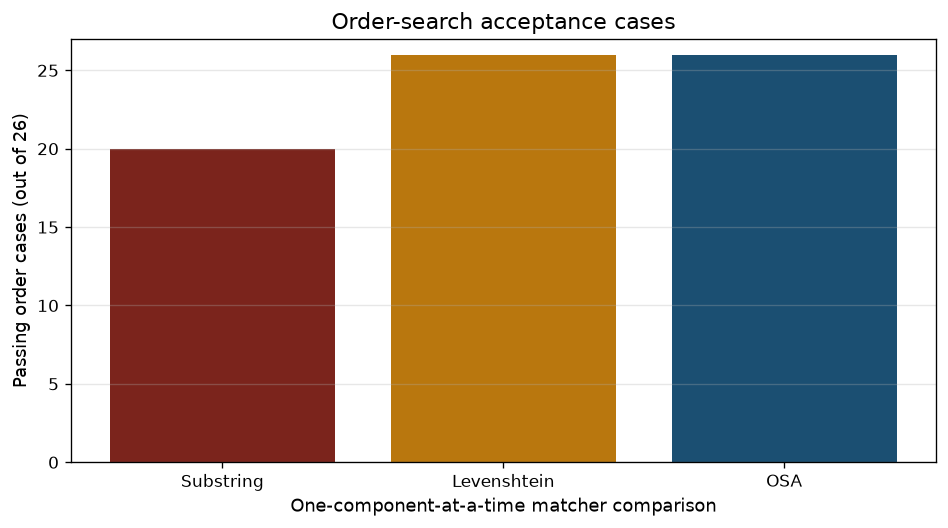

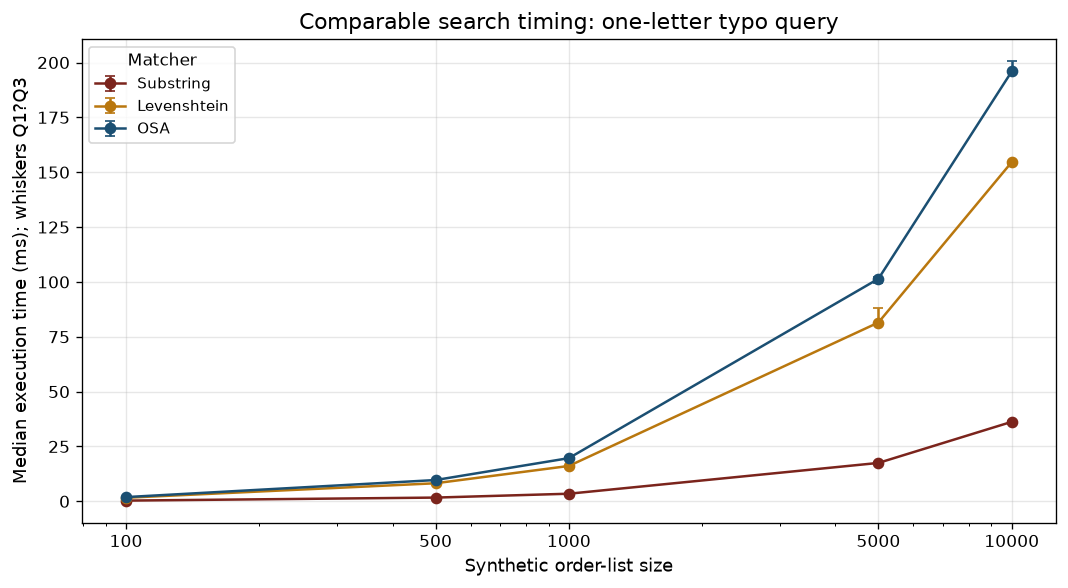

In [7]:
plt.rcParams.update({"axes.titlesize": 13, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 9, "figure.dpi": 120})

def show(fig):
    import io
    fig.tight_layout()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["Substring", "Levenshtein", "OSA"]
values = [SUBSTRING_PASSES, sum(row["passed"] for row in LEVEN_ORDERS), sum(row["passed"] for row in SPEC_ORDERS)]
ax.bar(labels, values, color=["#7b241c", "#b9770e", "#1b4f72"])
ax.set_ylim(0, len(ORDER_CASES) + 1)
ax.set_ylabel(f"Passing order cases (out of {len(ORDER_CASES)})")
ax.set_xlabel("One-component-at-a-time matcher comparison")
ax.set_title("Order-search acceptance cases")
ax.grid(True, axis="y", alpha=0.3)
show(fig)

fig, ax = plt.subplots(figsize=(9, 5))
colors = {"Substring": "#7b241c", "Levenshtein": "#b9770e", "OSA": "#1b4f72"}
for algorithm, color in colors.items():
    rows = [r for r in SEARCH_TIMING if r["algorithm"] == algorithm and r["query"] == "typo Santoz"]
    medians = [r["median_ms"] for r in rows]
    lower = [max(0, r["median_ms"] - r["q1_ms"]) for r in rows]
    upper = [max(0, r["q3_ms"] - r["median_ms"]) for r in rows]
    ax.errorbar([r["size"] for r in rows], medians, yerr=[lower, upper], marker="o", capsize=3, color=color, label=algorithm)
ax.set_xscale("log")
ax.set_xticks(SEARCH_SIZES)
ax.set_xticklabels([str(size) for size in SEARCH_SIZES])
ax.set_xlabel("Synthetic order-list size")
ax.set_ylabel("Median execution time (ms); whiskers Q1?Q3")
ax.set_title("Comparable search timing: one-letter typo query")
ax.legend(title="Matcher")
ax.grid(True, alpha=0.3)
show(fig)

## 8. Progressive nutrition ablation and mathematical model

For slot `i`, the candidate set has `n_i` eligible meals. The exhaustive solver enumerates the Cartesian product (`product(n_i)` plans), computes daily totals, and selects the feasible plan with minimum weighted deviation; if no feasible plan exists but every slot has candidates, it returns the closest plan and `ok=False`. Runtime is `O(product(n_i)*k)` for `k` slots; recursive-path storage is `O(k)` apart from candidate and selected-plan data.

For totals `(C,P,F)` and targets `(C_t,P_t,F_t)`, the score is `|C-C_t| + 4|P-P_t| + 2|F-F_t|`. Positive calorie and fat targets are upper bounds for `ok`; a positive protein target is a minimum only for `exactMatch`. Per-meal sorting uses the same weighted absolute deviation against the full daily target and only determines traversal/tie order. The greedy baseline independently selects the meal closest to an equal share of each daily target, `argmin_m (|C_m-C_t/k| + 4|P_m-P_t/k| + 2|F_m-F_t/k|)`, then checks that fixed selection through the solver; it does not search alternate combinations. Its scan is `O(sum(n_i))` plus the fixed-plan check, trading global search for lower effort.

Both methods receive identical candidate menus and targets within each comparison. An independent evaluator recomputes selected-plan totals, calorie/fat feasibility, protein attainment, and the same weighted score for both algorithms; it does not trust either algorithm's reported score or flags. Two fixed quality scenarios demonstrate an observed tie and an observed greedy miss. A separate seeded synthetic menu sweep varies meal values and measures scaling across candidate counts. Its quality results are also independently reevaluated; the timing sweep is not a substitute for the explicit quality scenarios. The greedy implementation includes its existing fixed-plan solver check, which is included in its measured runtime.


PASS | independent nutrition evaluation | tie and miss scenarios validated
PASS | nutrition | normal feasible plan
PASS | nutrition | no candidates in a slot
PASS | nutrition | duplicate candidate retained
PASS | nutrition | calorie/fat boundary is inclusive
PASS | nutrition | infeasible boundary returns closest plan
PASS | nutrition | invalid/non-finite number normalization
textbook exact {'calories': 1700.0, 'protein': 120.0, 'fat': 45.0} over ok False greedy exact on the known day True greedy score 0.0
per slot  4 combinations      64 exhaustive median    0.202 ms IQR    0.014 ms peak      3504 B | greedy median    0.029 ms IQR    0.003 ms peak      2544 B | independently evaluated ok/exact=True/True vs False/False; score=98.00/204.00
per slot  8 combinations     512 exhaustive median    1.390 ms IQR    0.025 ms peak      4798 B | greedy median    0.041 ms IQR    0.002 ms peak      2576 B | independently evaluated ok/exact=True/True vs True/True; score=45.00/112.00
per slot 12 combi

per slot 24 combinations   13824 exhaustive median   36.941 ms IQR    0.394 ms peak      4120 B | greedy median    0.090 ms IQR    0.001 ms peak      2296 B | independently evaluated ok/exact=True/True vs False/False; score=0.00/92.00


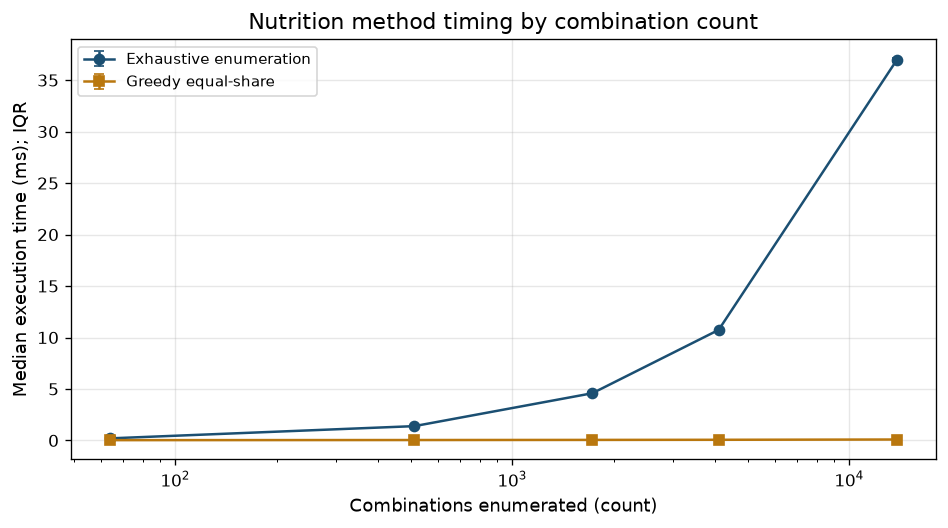

In [8]:
def number(value):
    try:
        numeric = float(value)
    except (TypeError, ValueError):
        return 0.0
    if numeric != numeric or numeric in (math.inf, -math.inf):
        return 0.0
    return numeric


def solve_nutrition_plan(meals, target, slots=None):
    if slots is None:
        slots = ["Breakfast", "Lunch", "Dinner"]
    available = [meal for meal in meals if meal.get("available") is not False]
    def finite(value):
        try:
            numeric = float(value)
        except (TypeError, ValueError):
            return False
        return numeric == numeric and numeric not in (math.inf, -math.inf)
    eligible = []
    for meal in available:
        keep = True
        for key in ("calories", "protein", "fat"):
            if number(target.get(key)) > 0 and not finite(meal.get(key)):
                keep = False
        if keep:
            eligible.append(meal)
    def candidate(meal):
        return (
            (1 if number(target.get("calories")) > 0 else 0) * abs(number(meal.get("calories")) - number(target.get("calories")))
            + (1 if number(target.get("protein")) > 0 else 0) * abs(number(meal.get("protein")) - number(target.get("protein"))) * 4
            + (1 if number(target.get("fat")) > 0 else 0) * abs(number(meal.get("fat")) - number(target.get("fat"))) * 2
        )
    by_slot = []
    for slot in slots:
        choices = [meal for meal in eligible if not meal.get("category") or meal.get("category") == slot]
        choices.sort(key=candidate)
        by_slot.append(choices)
    if any(len(choices) == 0 for choices in by_slot):
        return {"ok": False, "exactMatch": False, "meals": [], "totals": {"calories": 0, "protein": 0, "fat": 0}}
    def totals(selected):
        acc = {"calories": 0.0, "protein": 0.0, "fat": 0.0}
        for meal in selected:
            acc["calories"] += number(meal.get("calories"))
            acc["protein"] += number(meal.get("protein"))
            acc["fat"] += number(meal.get("fat"))
        return acc
    def deviation(summary):
        return abs(summary["calories"] - number(target.get("calories"))) + abs(summary["protein"] - number(target.get("protein"))) * 4 + abs(summary["fat"] - number(target.get("fat"))) * 2
    def within(summary):
        if number(target.get("calories")) > 0 and summary["calories"] > number(target.get("calories")):
            return False
        if number(target.get("fat")) > 0 and summary["fat"] > number(target.get("fat")):
            return False
        return True
    best = closest = None
    def visit(index, selected):
        nonlocal best, closest
        if index == len(by_slot):
            summary = totals(selected)
            score = deviation(summary)
            row = (list(selected), summary, score)
            if closest is None or score < closest[2]:
                closest = row
            if within(summary) and (best is None or score < best[2]):
                best = row
            return
        for meal in by_slot[index]:
            selected.append(meal)
            visit(index + 1, selected)
            selected.pop()
    visit(0, [])
    chosen = best or closest
    summary = chosen[1]
    exact = best is not None and within(summary) and not (number(target.get("protein")) > 0 and summary["protein"] < number(target.get("protein")))
    return {"ok": best is not None, "exactMatch": exact, "meals": chosen[0], "totals": summary, "score": chosen[2]}


def greedy_share(meals, target, slots=None):
    if slots is None:
        slots = ["Breakfast", "Lunch", "Dinner"]
    plan_slots = []
    for slot in slots:
        choices = [meal for meal in meals if meal.get("available") is not False and meal.get("category") == slot and number(meal.get("calories")) > 0]
        if not choices:
            return {"ok": False, "exactMatch": False, "meals": [], "totals": {"calories": 0, "protein": 0, "fat": 0}, "score": None}
        share = len(slots)
        def score(meal):
            return (
                abs(number(meal.get("calories")) - number(target.get("calories")) / share)
                + abs(number(meal.get("protein")) - number(target.get("protein")) / share) * 4
                + abs(number(meal.get("fat")) - number(target.get("fat")) / share) * 2
            )
        plan_slots.append(min(choices, key=score))
    solved = solve_nutrition_plan(plan_slots, target, slots)
    return solved


def evaluate_nutrition_selection(selected, target, slots=None):
    """Independently score a selected plan using the notebook's stated criteria."""
    if slots is None:
        slots = ["Breakfast", "Lunch", "Dinner"]
    totals = {key: sum(number(meal.get(key)) for meal in selected) for key in ("calories", "protein", "fat")}
    complete = len(selected) == len(slots) and all(sum(meal.get("category") == slot for meal in selected) == 1 for slot in slots)
    within_limits = (
        (number(target.get("calories")) <= 0 or totals["calories"] <= number(target.get("calories")))
        and (number(target.get("fat")) <= 0 or totals["fat"] <= number(target.get("fat")))
    )
    feasible = complete and within_limits
    exact = feasible and (number(target.get("protein")) <= 0 or totals["protein"] >= number(target.get("protein")))
    score = abs(totals["calories"] - number(target.get("calories"))) + 4 * abs(totals["protein"] - number(target.get("protein"))) + 2 * abs(totals["fat"] - number(target.get("fat"))) if complete else None
    return {"ok": feasible, "exactMatch": exact, "totals": totals, "score": score}

NUTRITION_TARGET = {"calories": 1800, "protein": 100, "fat": 60}
NUTRITION_SLOTS = ["Breakfast", "Lunch", "Dinner"]
NUTRITION_SCENARIOS = {
    "Greedy tie": [
        {"id": "B0", "category": "Breakfast", "calories": 550, "protein": 35, "fat": 28},
        {"id": "B1", "category": "Breakfast", "calories": 500, "protein": 15, "fat": 20},
        {"id": "B2", "category": "Breakfast", "calories": 800, "protein": 15, "fat": 28},
        {"id": "L0", "category": "Lunch", "calories": 550, "protein": 35, "fat": 8},
        {"id": "L1", "category": "Lunch", "calories": 500, "protein": 25, "fat": 12},
        {"id": "L2", "category": "Lunch", "calories": 700, "protein": 15, "fat": 32},
        {"id": "D0", "category": "Dinner", "calories": 700, "protein": 40, "fat": 12},
        {"id": "D1", "category": "Dinner", "calories": 400, "protein": 40, "fat": 28},
        {"id": "D2", "category": "Dinner", "calories": 800, "protein": 20, "fat": 24},
    ],
    "Greedy misses feasible optimum": [
        {"id": "B0", "category": "Breakfast", "calories": 400, "protein": 20, "fat": 32},
        {"id": "B1", "category": "Breakfast", "calories": 650, "protein": 50, "fat": 20},
        {"id": "B2", "category": "Breakfast", "calories": 550, "protein": 45, "fat": 20},
        {"id": "L0", "category": "Lunch", "calories": 800, "protein": 35, "fat": 12},
        {"id": "L1", "category": "Lunch", "calories": 350, "protein": 25, "fat": 16},
        {"id": "L2", "category": "Lunch", "calories": 350, "protein": 25, "fat": 20},
        {"id": "D0", "category": "Dinner", "calories": 450, "protein": 20, "fat": 28},
        {"id": "D1", "category": "Dinner", "calories": 400, "protein": 50, "fat": 16},
        {"id": "D2", "category": "Dinner", "calories": 500, "protein": 45, "fat": 28},
    ],
}

NUTRITION_SCENARIO_RESULTS = []
for scenario_name, menu in NUTRITION_SCENARIOS.items():
    methods = {
        "Exhaustive": lambda menu=menu: solve_nutrition_plan(menu, NUTRITION_TARGET, NUTRITION_SLOTS),
        "Greedy": lambda menu=menu: greedy_share(menu, NUTRITION_TARGET, NUTRITION_SLOTS),
    }
    for method_name, run_method in methods.items():
        stats = measure(run_method, SLOT_REPEATS)
        algorithm_output = run_method()
        quality = evaluate_nutrition_selection(algorithm_output["meals"], NUTRITION_TARGET, NUTRITION_SLOTS)
        check(algorithm_output["ok"] == quality["ok"], f"{scenario_name} {method_name} feasibility agrees with independent evaluation")
        check(algorithm_output["exactMatch"] == quality["exactMatch"], f"{scenario_name} {method_name} protein result agrees with independent evaluation")
        check(math.isclose(algorithm_output["score"], quality["score"], rel_tol=0, abs_tol=1e-9), f"{scenario_name} {method_name} score agrees with independent evaluation")
        NUTRITION_SCENARIO_RESULTS.append({"scenario": scenario_name, "method": method_name, "selected_ids": [meal["id"] for meal in algorithm_output["meals"]], "quality": quality, "stats": stats})

TIE_RESULTS = {row["method"]: row for row in NUTRITION_SCENARIO_RESULTS if row["scenario"] == "Greedy tie"}
MISS_RESULTS = {row["method"]: row for row in NUTRITION_SCENARIO_RESULTS if row["scenario"] == "Greedy misses feasible optimum"}
check(TIE_RESULTS["Exhaustive"]["quality"] == TIE_RESULTS["Greedy"]["quality"], "tie scenario has identical independently evaluated quality")
check(MISS_RESULTS["Exhaustive"]["quality"]["ok"] and MISS_RESULTS["Exhaustive"]["quality"]["exactMatch"] and MISS_RESULTS["Exhaustive"]["quality"]["score"] == 0, "miss scenario exhaustive plan meets all targets")
check(not MISS_RESULTS["Greedy"]["quality"]["ok"] and MISS_RESULTS["Greedy"]["quality"]["score"] > MISS_RESULTS["Exhaustive"]["quality"]["score"], "miss scenario greedy selection is less feasible/optimal")
print("PASS | independent nutrition evaluation | tie and miss scenarios validated")

TEXTBOOK = [
    {"id": "breakfast", "category": "Breakfast", "calories": 400, "protein": 25, "fat": 10},
    {"id": "lunch", "category": "Lunch", "calories": 600, "protein": 40, "fat": 15},
    {"id": "dinner", "category": "Dinner", "calories": 700, "protein": 55, "fat": 20},
]
exact_plan = solve_nutrition_plan(TEXTBOOK, {"calories": 1800, "protein": 120, "fat": 50})
over_plan = solve_nutrition_plan([
    {"id": "breakfast", "category": "Breakfast", "calories": 900, "protein": 20, "fat": 40},
    {"id": "lunch", "category": "Lunch", "calories": 900, "protein": 20, "fat": 40},
    {"id": "dinner", "category": "Dinner", "calories": 900, "protein": 20, "fat": 40},
], {"calories": 1800, "protein": 120, "fat": 50})
check(exact_plan["ok"] and exact_plan["exactMatch"] and exact_plan["totals"]["calories"] == 1700, "textbook exact")
check(over_plan["ok"] is False and over_plan["exactMatch"] is False and len(over_plan["meals"]) == 3, "textbook closest")
known = solve_nutrition_plan(TEXTBOOK, {"calories": 1700, "protein": 120, "fat": 45})
greedy_known = greedy_share(TEXTBOOK, {"calories": 1700, "protein": 120, "fat": 45})
check(known["exactMatch"] and known["score"] == 0, "known day")
NUTRITION_TESTS = [
    ("normal feasible plan", exact_plan["ok"] and exact_plan["exactMatch"]),
    ("no candidates in a slot", solve_nutrition_plan([], {"calories": 1800})["ok"] is False),
    ("duplicate candidate retained", len(solve_nutrition_plan(TEXTBOOK + [dict(TEXTBOOK[0])], {"calories": 1800, "protein": 120, "fat": 50})["meals"]) == 3),
    ("calorie/fat boundary is inclusive", solve_nutrition_plan(TEXTBOOK, {"calories": 1700, "protein": 120, "fat": 45})["ok"]),
    ("infeasible boundary returns closest plan", over_plan["ok"] is False and len(over_plan["meals"]) == 3),
    ("invalid/non-finite number normalization", number("not-a-number") == 0 and number(float("inf")) == 0),
]
for label, passed in NUTRITION_TESTS:
    print(f"{'PASS' if passed else 'FAIL'} | nutrition | {label}")
assert all(passed for _, passed in NUTRITION_TESTS), "one or more nutrition tests failed"
print("textbook exact", exact_plan["totals"], "over ok", over_plan["ok"], "greedy exact on the known day", greedy_known["exactMatch"], "greedy score", greedy_known["score"])

SLOT_TIMING = []
for per_slot in SLOT_SWEEP:
    meals = []
    rng = random.Random(DATASET_SEED + per_slot)
    for slot in ("Breakfast", "Lunch", "Dinner"):
        for index in range(per_slot):
            meals.append({"id": f"{slot[:1]}{index}", "category": slot, "calories": rng.randrange(300, 851, 25), "protein": rng.randrange(10, 61, 5), "fat": rng.randrange(5, 36, 3), "available": True})
    target = NUTRITION_TARGET
    combinations = per_slot ** 3
    solver = lambda meals=meals, target=target: solve_nutrition_plan(meals, target)
    greedy = lambda meals=meals, target=target: greedy_share(meals, target)
    solver_stats = measure(solver, SLOT_REPEATS)
    greedy_stats = measure(greedy, SLOT_REPEATS)
    solver_result, greedy_result = solver(), greedy()
    solver_quality = evaluate_nutrition_selection(solver_result["meals"], target)
    greedy_quality = evaluate_nutrition_selection(greedy_result["meals"], target)
    check(solver_result["ok"] == solver_quality["ok"] and solver_result["exactMatch"] == solver_quality["exactMatch"], "sweep exhaustive output agrees with independent evaluator")
    check(greedy_result["ok"] == greedy_quality["ok"] and greedy_result["exactMatch"] == greedy_quality["exactMatch"], "sweep greedy output agrees with independent evaluator")
    check(math.isclose(solver_result["score"], solver_quality["score"], rel_tol=0, abs_tol=1e-9), "sweep exhaustive score agrees with independent evaluator")
    check(math.isclose(greedy_result["score"], greedy_quality["score"], rel_tol=0, abs_tol=1e-9), "sweep greedy score agrees with independent evaluator")
    SLOT_TIMING.append({"per_slot": per_slot, "combinations": combinations, "solver": solver_stats, "greedy": greedy_stats, "solver_quality": solver_quality, "greedy_quality": greedy_quality})
    print(f"per slot {per_slot:>2} combinations {combinations:>7} exhaustive median {solver_stats['median_ms']:8.3f} ms IQR {solver_stats['iqr_ms']:8.3f} ms peak {solver_stats['peak_bytes']:>9} B | greedy median {greedy_stats['median_ms']:8.3f} ms IQR {greedy_stats['iqr_ms']:8.3f} ms peak {greedy_stats['peak_bytes']:>9} B | independently evaluated ok/exact={solver_quality['ok']}/{solver_quality['exactMatch']} vs {greedy_quality['ok']}/{greedy_quality['exactMatch']}; score={solver_quality['score']:.2f}/{greedy_quality['score']:.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for label, key, color, marker in (("Exhaustive enumeration", "solver", "#1b4f72", "o"), ("Greedy equal-share", "greedy", "#b9770e", "s")):
    medians = [row[key]["median_ms"] for row in SLOT_TIMING]
    lower = [max(0, row[key]["median_ms"] - row[key]["q1_ms"]) for row in SLOT_TIMING]
    upper = [max(0, row[key]["q3_ms"] - row[key]["median_ms"]) for row in SLOT_TIMING]
    ax.errorbar([row["combinations"] for row in SLOT_TIMING], medians, yerr=[lower, upper], marker=marker, color=color, capsize=3, label=label)
ax.set_xscale("log")
ax.set_xlabel("Combinations enumerated (count)")
ax.set_ylabel("Median execution time (ms); IQR")
ax.set_title("Nutrition method timing by combination count")
ax.legend()
ax.grid(True, alpha=0.3)
show(fig)


## 9. Failure analysis and consolidated summary

The next cell derives counts, timings, memory values, and failure rows from the acceptance cases or fresh benchmark measurements produced above. It reports observed mismatches with query, expected IDs, actual IDs, and a failure category; it does not invent failures. Search quality is evaluated only on workbook examples. Runtime and memory use only separately labeled synthetic data. Nutrition quality and cost are compared on the same synthetic meal menu and target at the largest measured slot size.


In [9]:
from IPython.display import Markdown, display

def run_search_evaluation(kind):
    order_rows = []
    for difficulty, role, query, status, expected in ORDER_CASES:
        if kind == "Substring": got = ids_of(substring_search(ORDERS, query, role, status, order_words))
        else:
            distance = levenshtein if kind == "Levenshtein" else osa_distance
            got = ids_of(search_records(ORDERS, query, role, status, distance, order_words))
        order_rows.append({"case": difficulty, "role": role, "query": query, "expected": expected, "got": got, "passed": got == expected})
    faq_rows = []
    for label, query, expected in FAQ_CASES:
        if kind == "Substring": got = ids_of(substring_search(FAQ, query, "faq", words_of=faq_words))
        else:
            distance = levenshtein if kind == "Levenshtein" else osa_distance
            got = ids_of(search_records(FAQ, query, "faq", None, distance, faq_words))
        faq_rows.append({"case": label, "role": "FAQ", "query": query, "expected": expected, "got": got, "passed": got == expected})
    return order_rows + faq_rows

SEARCH_EVALUATION = {name: run_search_evaluation(name) for name in ("Substring", "Levenshtein", "OSA")}
def category_for(row, algorithm):
    if row["query"].lstrip("#").isdigit(): return "strict order-number rule"
    if row["role"] == "staff" and row["query"].lower() in {"reyes", "santos", "villanueba"}: return "role-hidden field"
    if algorithm == "Substring" and row["expected"] and not row["got"]:
        return "multi-token spelling correction unavailable" if len(normalize(row["query"]).split()) > 1 else "spelling correction unavailable"
    return "ordered-result mismatch"
failures = []
for algorithm, rows in SEARCH_EVALUATION.items():
    for row in rows:
        if not row["passed"]: failures.append({"algorithm": algorithm, **row, "category": category_for(row, algorithm)})

lines = ["### Search acceptance: same 33 workbook cases (26 order + 7 FAQ)", "| Matcher | Order passed | FAQ passed | Total exact-list pass |", "|---|---:|---:|---:|"]
for algorithm, rows in SEARCH_EVALUATION.items():
    order = [r for r in rows if r["role"] != "FAQ"]
    faq = [r for r in rows if r["role"] == "FAQ"]
    lines.append(f"| {algorithm} | {sum(r['passed'] for r in order)}/{len(order)} | {sum(r['passed'] for r in faq)}/{len(faq)} | {sum(r['passed'] for r in rows)}/{len(rows)} |")
lines += ["", "### Observed failure-mode breakdown", "| Matcher | Input | Expected IDs | Actual IDs | Failure category |", "|---|---|---|---|---|"]
if failures:
    for row in failures: lines.append(f"| {row['algorithm']} | `{row['query']}` ({row['role']}) | `{row['expected']}` | `{row['got']}` | {row['category']} |")
else: lines.append("| ? | No acceptance mismatches observed | ? | ? | ? |")
large_search = [r for r in SEARCH_TIMING if r["size"] == 10000 and r["query"] == "typo Santoz"]
lines += ["", "### Synthetic search efficiency (10,000 generated orders, `Santoz`)", "| Matcher | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |", "|---|---:|---:|---:|---:|---:|"]
for row in large_search: lines.append(f"| {row['algorithm']} | {row['median_ms']:.3f} | {row['q1_ms']:.3f} | {row['q3_ms']:.3f} | {row['iqr_ms']:.3f} | {row['peak_bytes']} |")
lines += ["", "### Controlled nutrition quality scenarios (same menu and targets per pair)", "These explicitly defined scenarios are diagnostic fixtures, not a random sample of meals. Both methods receive the identical menu and 1,800 kcal / 100 g protein / 60 g fat target within a scenario. Selected-plan quality is recomputed by `evaluate_nutrition_selection`, independently of either method's reported result.", "| Scenario | Method | Selected IDs | Feasible (`ok`) | Protein target (`exactMatch`) | Score | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |", "|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for row in NUTRITION_SCENARIO_RESULTS:
    quality, stats = row["quality"], row["stats"]
    ids = ", ".join(row["selected_ids"])
    lines.append(f"| {row['scenario']} | {row['method']} | `{ids}` | {quality['ok']} | {quality['exactMatch']} | {quality['score']:.2f} | {stats['median_ms']:.3f} | {stats['q1_ms']:.3f} | {stats['q3_ms']:.3f} | {stats['iqr_ms']:.3f} | {stats['peak_bytes']} |")

last = SLOT_TIMING[-1]
lines += ["", f"### Seeded nutrition performance sweep ({last['per_slot']} candidates per slot; {last['combinations']:,} combinations)", "| Method | Feasible (`ok`) | Protein target (`exactMatch`) | Score | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |", "|---|---:|---:|---:|---:|---:|---:|---:|---:|"]
for label, key in (("Exhaustive enumeration", "solver"), ("Greedy equal-share", "greedy")):
    stats, quality = last[key], last[f"{key}_quality"]
    lines.append(f"| {label} | {quality['ok']} | {quality['exactMatch']} | {quality['score']:.2f} | {stats['median_ms']:.3f} | {stats['q1_ms']:.3f} | {stats['q3_ms']:.3f} | {stats['iqr_ms']:.3f} | {stats['peak_bytes']} |")

lines += ["", "### Interpretation tied to the problem statement", "Search ablation shows whether each progressively richer matching rule recovers workbook typo-tolerant order/FAQ cases while preserving staff visibility and order-number constraints. Runtime and memory above are measured only on separately generated synthetic order lists, not real customer data. In the fixed nutrition tie fixture both methods selected equal-quality plans; in the fixed miss fixture, exhaustive enumeration found a feasible zero-score plan while greedy did not. These are constructed diagnostics, not estimates of how often either outcome occurs in a real menu. The separate seeded sweep measures scaling and reports independently evaluated quality at each size. OSA's diagnostic shows its transposition capability under the existing typo threshold; the measured search timings display its extra computational cost. None of these synthetic results establishes production latency or clinical suitability."]
display(Markdown("\n".join(lines)))

### Search acceptance: same 33 workbook cases (26 order + 7 FAQ)
| Matcher | Order passed | FAQ passed | Total exact-list pass |
|---|---:|---:|---:|
| Substring | 20/26 | 4/7 | 24/33 |
| Levenshtein | 26/26 | 7/7 | 33/33 |
| OSA | 26/26 | 7/7 | 33/33 |

### Observed failure-mode breakdown
| Matcher | Input | Expected IDs | Actual IDs | Failure category |
|---|---|---|---|---|
| Substring | `Mria` (admin) | `['00349']` | `[]` | spelling correction unavailable |
| Substring | `carols` (admin) | `['00348']` | `[]` | spelling correction unavailable |
| Substring | `Villanueba` (admin) | `['00346']` | `[]` | spelling correction unavailable |
| Substring | `Mria` (admin) | `['00349']` | `[]` | spelling correction unavailable |
| Substring | `Mria` (staff) | `['00349']` | `[]` | spelling correction unavailable |
| Substring | `carols` (staff) | `['00348']` | `[]` | spelling correction unavailable |
| Substring | `pasword` (FAQ) | `['account-password', 'account-google']` | `[]` | spelling correction unavailable |
| Substring | `reset pasword` (FAQ) | `['account-password']` | `[]` | multi-token spelling correction unavailable |
| Substring | `delivry` (FAQ) | `['ordering-place', 'delivery-window']` | `[]` | spelling correction unavailable |

### Synthetic search efficiency (10,000 generated orders, `Santoz`)
| Matcher | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |
|---|---:|---:|---:|---:|---:|
| Substring | 36.234 | 35.141 | 36.657 | 1.516 | 93139 |
| Levenshtein | 154.611 | 153.942 | 154.885 | 0.943 | 139151 |
| OSA | 195.916 | 195.696 | 200.701 | 5.005 | 139151 |

### Controlled nutrition quality scenarios (same menu and targets per pair)
These explicitly defined scenarios are diagnostic fixtures, not a random sample of meals. Both methods receive the identical menu and 1,800 kcal / 100 g protein / 60 g fat target within a scenario. Selected-plan quality is recomputed by `evaluate_nutrition_selection`, independently of either method's reported result.
| Scenario | Method | Selected IDs | Feasible (`ok`) | Protein target (`exactMatch`) | Score | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Greedy tie | Exhaustive | `B0, L0, D0` | True | True | 64.00 | 0.097 | 0.096 | 0.098 | 0.002 | 2536 |
| Greedy tie | Greedy | `B0, L0, D0` | True | True | 64.00 | 0.038 | 0.031 | 0.044 | 0.013 | 2208 |
| Greedy misses feasible optimum | Exhaustive | `B2, L0, D0` | True | True | 0.00 | 0.103 | 0.101 | 0.103 | 0.002 | 2952 |
| Greedy misses feasible optimum | Greedy | `B2, L0, D2` | False | False | 150.00 | 0.022 | 0.022 | 0.023 | 0.001 | 2512 |

### Seeded nutrition performance sweep (24 candidates per slot; 13,824 combinations)
| Method | Feasible (`ok`) | Protein target (`exactMatch`) | Score | Median ms | Q1 ms | Q3 ms | IQR ms | Peak traced bytes |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Exhaustive enumeration | True | True | 0.00 | 36.941 | 36.746 | 37.141 | 0.394 | 4120 |
| Greedy equal-share | False | False | 92.00 | 0.090 | 0.090 | 0.091 | 0.001 | 2296 |

### Interpretation tied to the problem statement
Search ablation shows whether each progressively richer matching rule recovers workbook typo-tolerant order/FAQ cases while preserving staff visibility and order-number constraints. Runtime and memory above are measured only on separately generated synthetic order lists, not real customer data. In the fixed nutrition tie fixture both methods selected equal-quality plans; in the fixed miss fixture, exhaustive enumeration found a feasible zero-score plan while greedy did not. These are constructed diagnostics, not estimates of how often either outcome occurs in a real menu. The separate seeded sweep measures scaling and reports independently evaluated quality at each size. OSA's diagnostic shows its transposition capability under the existing typo threshold; the measured search timings display its extra computational cost. None of these synthetic results establishes production latency or clinical suitability.

## 10. Limitations

- The order/FAQ matcher implements workbook wording and examples. Expo order/FAQ search boxes are not claimed to use this Python implementation.
- The meal-catalog `fuzzySearchMeals` rule is distinct and excluded; its query semantics must not be inferred from these measurements.
- Kitchen and Delivery share one matcher because supplied criteria specify the same fields and limits. "Newest" in the sample follows row stamps; live data would use stored timestamps.
- `350` is treated as full order number `00350` without leading zeros. Workbook examples do not settle every shorter digit fragment or malformed record.
- FAQ outcomes follow current wording in `frontend/src/data/helpContent.ts`; `delivry` includes answers containing a close form of "delivery". Google FAQ also contains "password", so an exact password query returns two entries.
- Synthetic names are timing fixtures, not a customer database. Size, word distribution, language, and duplicate frequency are not representative workload estimates.
- Nutrition benchmark data is synthetic. The current solver can enumerate `24^3 = 13,824` combinations, but much larger candidate sets grow exponentially in slot count. No claim is made about hundreds of meals per slot or JavaScript runtime.
- `tracemalloc` captures Python-traced allocations for one call, not native, OS, mobile-device, or whole-process memory. Five timing repeats are a small teaching benchmark, not a production latency guarantee.
- No password, API key, or hosted database was used. This is not a clinical nutrition recommendation.


## 11. Related studies and references

Recent notebook-reproducibility research measures the reproducibility of computational notebooks at scale (Samuel & Mietchen, 2024), motivating this report's clean-kernel rerun and dependency/context reporting. The Eurobench software approach describes standardized scoring inputs and outputs for reproducible and comparable experiments (Remazeilles et al., 2022), which motivates the controlled, same-input ablations here. Huang et al. (2022) review computational-model evaluation and explicitly discuss ablation studies and computational-cost reporting, supporting the use of controlled variants and measured cost here. Their microRNA-disease prediction domain differs from this application, so the citation motivates methodology rather than any algorithmic conclusion. Varoquaux and Cheplygina (2022) discuss methodological failures in model evaluation and the need to keep data and evaluation claims bounded. Our ablation changes one search component at a time and holds nutrition menus and targets constant. These studies inform methodology; they are not evidence about F.I.L. Foods' measured outcomes.

### Foundational algorithm references

Damerau, F. J. (1964). A technique for computer detection and correction of spelling errors. *Communications of the ACM, 7*(3), 171-176. https://doi.org/10.1145/363958.363994

Levenshtein, V. I. (1966). Binary codes capable of correcting deletions, insertions, and reversals. *Soviet Physics Doklady, 10*(8), 707-710.

Wagner, R. A., & Fischer, M. J. (1974). The string-to-string correction problem. *Journal of the ACM, 21*(1), 168-173. https://doi.org/10.1145/321796.321811

Navarro, G. (2001). A guided tour to approximate string matching. *ACM Computing Surveys, 33*(1), 31-88. https://doi.org/10.1145/375360.375365

### Recent peer-reviewed work (2022-2024)

Samuel, S., & Mietchen, D. (2024). Computational reproducibility of Jupyter notebooks from biomedical publications. *GigaScience, 13*, giad113. https://doi.org/10.1093/gigascience/giad113

Remazeilles, A., Dominguez, A., Barralon, P., Torres-Pardo, A., Pinto, D., Aller, F., Mombaur, K., Conti, R., Saccares, L., Thorsteinsson, F., Prinsen, E., Cantón, A., Castilla, J., Sanz-Morère, C. B., Tornero, J., & Torricelli, D. (2022). Making bipedal robot experiments reproducible and comparable: The Eurobench software approach. *Frontiers in Robotics and AI, 9*, 951663. https://doi.org/10.3389/frobt.2022.951663

Varoquaux, G., & Cheplygina, V. (2022). Machine learning for medical imaging: methodological failures and recommendations for the future. *npj Digital Medicine, 5*, Article 48. https://doi.org/10.1038/s41746-022-00592-y

Huang, L., Zhang, L., & Chen, X. (2022). Updated review of advances in microRNAs and complex diseases: towards systematic evaluation of computational models. *Briefings in Bioinformatics, 23*(6), bbac407. https://doi.org/10.1093/bib/bbac407

Python Software Foundation. `time.perf_counter` and `tracemalloc`. Python 3 documentation. https://docs.python.org/3/library/time.html#time.perf_counter and https://docs.python.org/3/library/tracemalloc.html

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55

Project-specific sources: acceptance examples ADM-11, KIT-11, DEL-11, and USR-27; FAQ wording in `frontend/src/data/helpContent.ts`; TypeScript solver in `frontend/src/services/nutritionService.ts`; separate meal-catalog matcher in `frontend/src/services/orderService.ts`.
